# Calcular el estilo del equipo

## Librerías

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from pathlib import Path

## Constantes de configuración

In [2]:
# Pesos por temporada: la 25/26 pesa más porque es la más reciente y en el mismo nivel
PESOS_TEMPORADAS = [0.15, 0.15, 0.70]

METRICAS_ESTILO = [
    'xG', 'Shots_on target_%', 'Possession, %', 'PPDA',
    'Passes to final third_Total', 'Average passes per possession',
    'Recoveries_High', 'Recoveries_Medium', 'Recoveries_Low',
    'Counterattacks_with shots', 'Touches in penalty area',
    'Fouls', 'Conceded goals', 'Shots against_on target_%', 'Lateral passes_Total'
]

# Interpretación de los componentes resultantes del PCA
NOMBRES_COMPONENTES = {
    'C1': 'C1: Dominio Asociativo',
    'C2': 'C2: Resiliencia Defensiva',
    'C3': 'C3: Verticalidad y Pegada',
    'C4': 'C4: Fragilidad (Goles/Tiros)',
    'C5': 'C5: Disrupción (Faltas)'
}

# Paleta de colores corporativa UDLP
COLOR_AZUL = '#003057'
COLOR_AMARILLO = '#FFD700'
COLOR_POSITIVO = '#11CAA0'
COLOR_NEGATIVO = '#FF4B4B'

## Limpieza Wyscout

In [3]:
def limpiar_dataset_scouting(ruta_archivo):
    """
    Procesa el Excel de Wyscout renombrando columnas compuestas y eliminando
    las filas de cabecera residuales. Funciona para cualquier exportación de equipo.
    """
    df = pd.read_excel(ruta_archivo)

    nuevas_columnas = []
    sub_metricas_pendientes = []

    for col in df.columns:
        col_str = str(col)

        if not col_str.startswith('Unnamed'):
            if ' / ' in col_str:
                partes = [p.strip() for p in col_str.split('/')]
                metrica_base = partes[0]
                nuevas_columnas.append(f'{metrica_base}_Total')

                if len(partes) == 2:
                    sub_metricas_pendientes = [
                        f'{metrica_base}_{partes[1]}',
                        f'{metrica_base}_{partes[1]}_%'
                    ]
                else:
                    sub_metricas_pendientes = [f'{metrica_base}_{p}' for p in partes[1:]]
            else:
                nuevas_columnas.append(col_str)
                sub_metricas_pendientes = []
        else:
            if sub_metricas_pendientes:
                nuevas_columnas.append(sub_metricas_pendientes.pop(0))
            else:
                nuevas_columnas.append(col_str)

    df.columns = nuevas_columnas
    df_limpio = df.dropna(subset=['Date', 'Match']).reset_index(drop=True)

    print(f'Limpieza OK: {ruta_archivo.name} — {len(df_limpio.columns)} columnas')
    return df_limpio

In [4]:

def cargar_temporadas(rutas, pesos):
    """
    Carga múltiples archivos de Wyscout, les asigna etiqueta de temporada y peso,
    y los concatena en un único DataFrame listo para el análisis.
    """
    nombres_temporadas = ['Temp_2324', 'Temp_2425', 'Temp_2526']
    lista_dfs = []

    for ruta, peso, nombre in zip(rutas, pesos, nombres_temporadas):
        df_temp = limpiar_dataset_scouting(ruta)
        df_temp['Temporada'] = nombre
        df_temp['Peso_Temp'] = peso
        lista_dfs.append(df_temp)

    return pd.concat(lista_dfs, ignore_index=True)

In [5]:
ruta_base = Path.cwd().parent.parent / 'data' / 'udlaspalmas'

# Si aún no tienes los excels en la carpeta data, esto fallará
rutas_temporadas = [
    ruta_base / 'Team Stats Las Palmas 2324.xlsx',
    ruta_base / 'Team Stats Las Palmas 2425.xlsx',
    ruta_base / 'Team Stats Las Palmas.xlsx',
]

df_global = cargar_temporadas(rutas_temporadas, PESOS_TEMPORADAS)

Limpieza OK: Team Stats Las Palmas 2324.xlsx — 46 columnas
Limpieza OK: Team Stats Las Palmas 2425.xlsx — 46 columnas
Limpieza OK: Team Stats Las Palmas.xlsx — 46 columnas


## Análisis de Componentes Principales

In [6]:
def ejecutar_pipeline_pca(df, metricas, n_componentes=5):
    """
    Escala las métricas, aplica PCA y devuelve el DataFrame enriquecido
    con los componentes calculados junto con el modelo entrenado.
    """
    df_agrupado = df.groupby(['Team', 'Temporada', 'Peso_Temp'])[metricas].mean().reset_index()

    scaler = StandardScaler()
    datos_escalados = scaler.fit_transform(df_agrupado[metricas])

    pca = PCA(n_components=n_componentes)
    componentes = pca.fit_transform(datos_escalados)

    for i in range(n_componentes):
        df_agrupado[f'C{i+1}'] = componentes[:, i]

    return df_agrupado, pca, scaler


df_pca, modelo_pca, scaler = ejecutar_pipeline_pca(df_global, METRICAS_ESTILO)

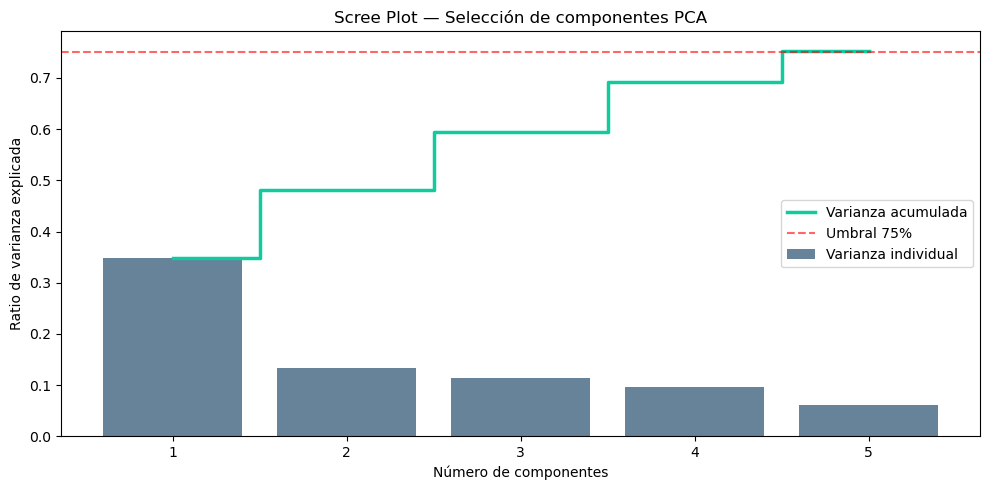

In [7]:
def graficar_scree_plot(pca_modelo):
    """Muestra qué porcentaje de varianza explica cada componente principal."""
    varianza = pca_modelo.explained_variance_ratio_
    varianza_acumulada = np.cumsum(varianza)

    plt.figure(figsize=(10, 5))
    plt.bar(range(1, len(varianza) + 1), varianza, alpha=0.6,
            color=COLOR_AZUL, label='Varianza individual')
    plt.step(range(1, len(varianza_acumulada) + 1), varianza_acumulada,
             where='mid', color=COLOR_POSITIVO, linewidth=2.5, label='Varianza acumulada')
    plt.axhline(y=0.75, color='red', linestyle='--', alpha=0.6, label='Umbral 75%')
    plt.xlabel('Número de componentes')
    plt.ylabel('Ratio de varianza explicada')
    plt.title('Scree Plot — Selección de componentes PCA')
    plt.xticks(range(1, len(varianza) + 1))
    plt.legend()
    plt.tight_layout()
    plt.show()


graficar_scree_plot(modelo_pca)

## Perfil de estilo ponderado de Las Palmas

In [8]:
def calcular_perfil_ponderado(df_pca, nombre_equipo, columnas_componentes):
    """
    Calcula el centroide ponderado de un equipo en el espacio PCA.
    Los pesos aseguran que las temporadas más recientes influyen más en el resultado.
    """
    df_equipo = df_pca[df_pca['Team'] == nombre_equipo].copy()

    centroide = {}
    for col in columnas_componentes:
        clave = f'{col}_Obj'
        centroide[clave] = np.average(df_equipo[col], weights=df_equipo['Peso_Temp'])

    return centroide


cols_componentes = ['C1', 'C2', 'C3', 'C4', 'C5']
centroide_estilo = calcular_perfil_ponderado(df_pca, 'Las Palmas', cols_componentes)

print('Perfil de estilo ponderado (5D):')
for k, v in centroide_estilo.items():
    print(f'  {NOMBRES_COMPONENTES.get(k.replace("_Obj", ""), k):35s}: {v:+.3f}')

Perfil de estilo ponderado (5D):
  C1: Dominio Asociativo             : +1.335
  C2: Resiliencia Defensiva          : -0.645
  C3: Verticalidad y Pegada          : -0.668
  C4: Fragilidad (Goles/Tiros)       : +0.094
  C5: Disrupción (Faltas)            : -0.014


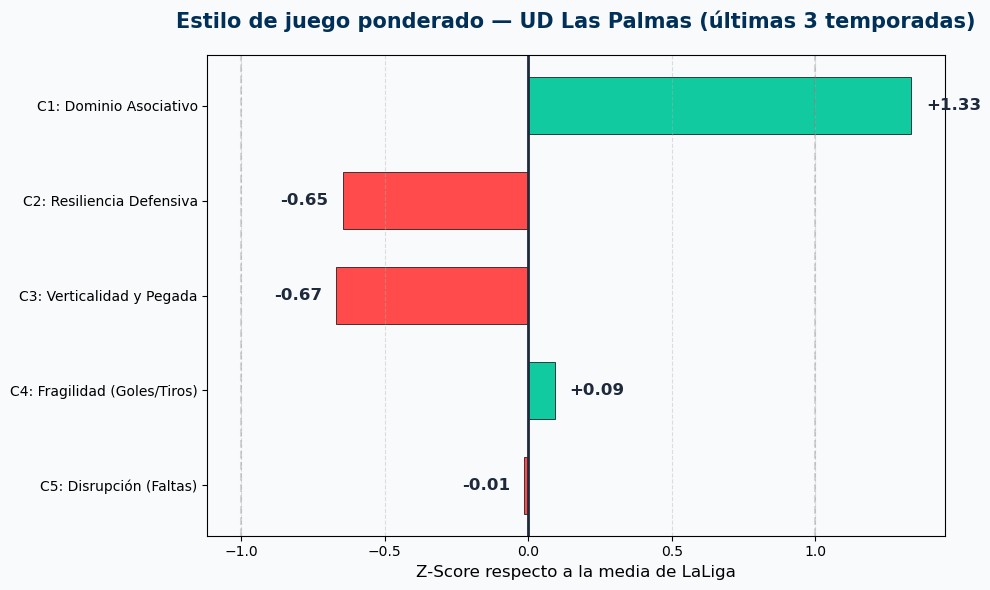

In [9]:
def graficar_estilo_barras(centroide, nombres_componentes):
    """Visualiza el perfil de estilo como barras horizontales."""
    ejes = list(nombres_componentes.values())
    valores = list(centroide.values())
    colores = [COLOR_POSITIVO if v > 0 else COLOR_NEGATIVO for v in valores]

    fig, ax = plt.subplots(figsize=(10, 6), facecolor='#F8FAFC')
    ax.set_facecolor('#F8FAFC')

    barras = ax.barh(ejes, valores, color=colores, height=0.6, edgecolor='black', linewidth=0.5)

    ax.axvline(x=0, color='#1E293B', linewidth=2)
    ax.axvline(x=-1, color='gray', linestyle='--', alpha=0.3)
    ax.axvline(x=1, color='gray', linestyle='--', alpha=0.3)

    for barra, val in zip(barras, valores):
        offset = 0.05 if val > 0 else -0.05
        ha = 'left' if val > 0 else 'right'
        ax.text(val + offset, barra.get_y() + barra.get_height() / 2,
                f'{val:+.2f}', va='center', ha=ha, fontsize=12,
                fontweight='bold', color='#1E293B')

    ax.set_title('Estilo de juego ponderado — UD Las Palmas (últimas 3 temporadas)',
                 fontsize=15, fontweight='bold', color=COLOR_AZUL, pad=20)
    ax.set_xlabel('Z-Score respecto a la media de LaLiga', fontsize=12)
    ax.grid(axis='x', linestyle='--', alpha=0.4)
    ax.invert_yaxis()
    plt.tight_layout()
    plt.show()


graficar_estilo_barras(centroide_estilo, NOMBRES_COMPONENTES)

## Evolución del estilo por temporada

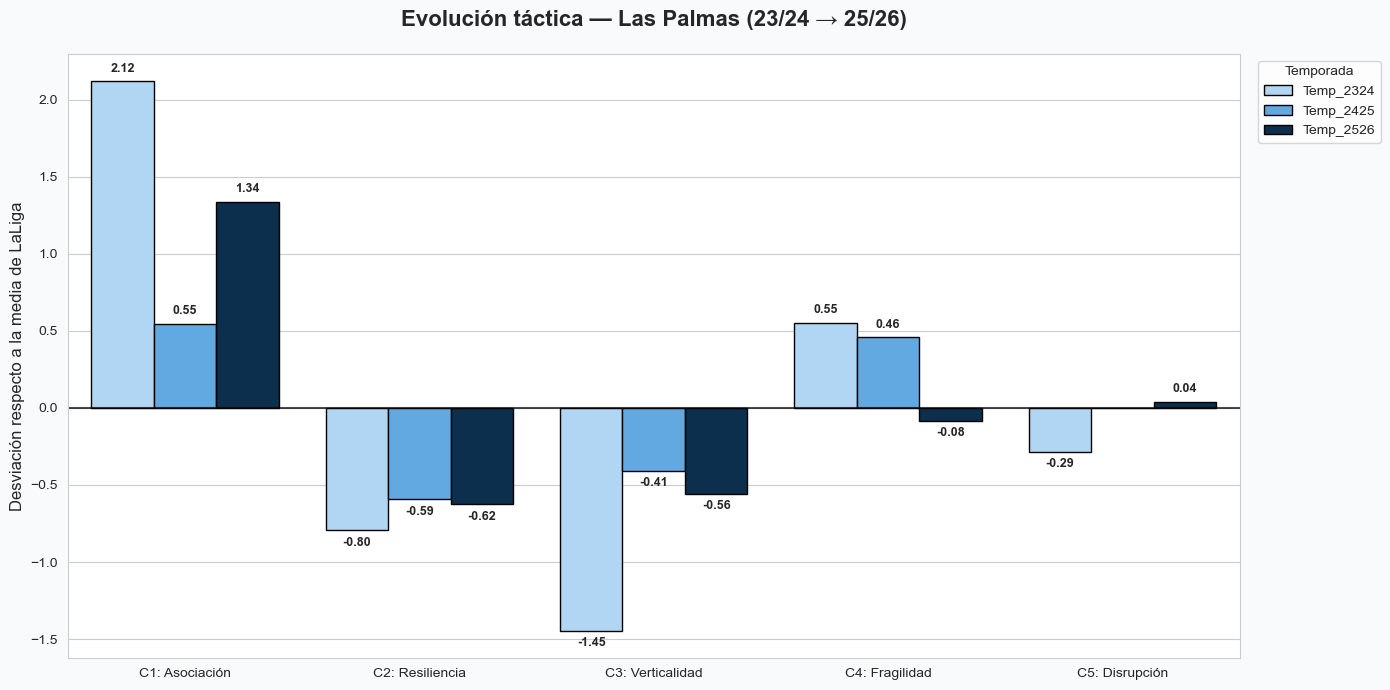

In [12]:
def graficar_evolucion_temporal(df_pca, nombre_equipo, columnas, nombres):
    """Muestra cómo ha evolucionado el estilo del equipo a lo largo de las temporadas."""
    df_equipo = df_pca[df_pca['Team'] == nombre_equipo].copy()

    df_plot = df_equipo.melt(
        id_vars=['Temporada'],
        value_vars=columnas,
        var_name='Componente',
        value_name='Z-Score'
    )
    df_plot['Componente'] = df_plot['Componente'].map(dict(zip(columnas, nombres)))

    plt.figure(figsize=(14, 7), facecolor='#F8FAFC')
    sns.set_style('whitegrid')

    paleta = ['#A5D8FF', '#4DABF7', COLOR_AZUL]
    ax = sns.barplot(data=df_plot, x='Componente', y='Z-Score',
                     hue='Temporada', palette=paleta,
                     edgecolor='black', linewidth=1)

    ax.axhline(y=0, color='black', linewidth=1.5, alpha=0.7)
    ax.set_title(f'Evolución táctica — {nombre_equipo} (23/24 → 25/26)',
                 fontsize=16, fontweight='bold', pad=20)
    ax.set_ylabel('Desviación respecto a la media de LaLiga', fontsize=12)
    ax.set_xlabel('')
    ax.legend(title='Temporada', bbox_to_anchor=(1.01, 1), loc='upper left')

    for parche in ax.patches:
        if abs(parche.get_height()) > 0.01:
            ax.annotate(
                f'{parche.get_height():.2f}',
                (parche.get_x() + parche.get_width() / 2, parche.get_height()),
                ha='center', va='center',
                xytext=(0, 9 if parche.get_height() > 0 else -9),
                textcoords='offset points',
                fontsize=9, fontweight='bold'
            )

    plt.tight_layout()
    plt.show()


nombres_cortos = ['C1: Asociación', 'C2: Resiliencia', 'C3: Verticalidad',
                  'C4: Fragilidad', 'C5: Disrupción']
graficar_evolucion_temporal(df_pca, 'Las Palmas', cols_componentes, nombres_cortos)

## Exportar el perfil de estilo

In [13]:
def guardar_perfil_estilo(centroide, ruta_destino):
    """Guarda el vector de estilo como CSV para que lo use el módulo de scouting."""
    ruta_destino = Path(ruta_destino)
    ruta_destino.mkdir(parents=True, exist_ok=True)

    df_centroide = pd.DataFrame([centroide])
    ruta_archivo = ruta_destino / 'perfil_estilo_udlp.csv'
    df_centroide.to_csv(ruta_archivo, index=False, encoding='utf-8-sig')

    print(f'Perfil de estilo guardado en: {ruta_archivo}')


ruta_data = Path.cwd().parent.parent / 'data' / 'udlaspalmas'
guardar_perfil_estilo(centroide_estilo, ruta_data)

Perfil de estilo guardado en: c:\Users\Usuario\tfm\data\udlaspalmas\perfil_estilo_udlp.csv
